# Homework 5

**Name:** Karan Verma  
**GitHub Username:** kv304  
**USC ID:** 5639810577

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 5)

RANDOM_STATE = 552
DATA_DIR = Path("data")

## 1. Decision Trees as Interpretable Models

### 1(a) Load and prepare the Acute Inflammations data

In [2]:
acute_columns = [
    "Temperature",
    "Nausea",
    "Lumbar pain",
    "Urine pushing",
    "Urination pain",
    "Burning",
    "Bladder inflammation",
    "Nephritis",
]

acute_data = pd.read_csv(
    DATA_DIR / "diagnosis.data",
    sep="\t",
    header=None,
    encoding="utf-16",
    decimal=",",
).dropna(axis=1, how="all")
acute_data.columns = acute_columns

for column in acute_columns[1:]:
    acute_data[column] = acute_data[column].map({"no": 0, "yes": 1})

symptom_names = acute_columns[:6]
symptoms = acute_data[symptom_names].astype(float)

# Label powerset: represent the two binary diagnoses as four joint classes.
diagnosis_class = (
    "Bladder=" + acute_data["Bladder inflammation"].astype(str)
    + ", Nephritis=" + acute_data["Nephritis"].astype(str)
)

display(acute_data.head())
print("Data shape:", acute_data.shape)
display(diagnosis_class.value_counts().rename("count").to_frame())

,Temperature,Nausea,Lumbar pain,Urine pushing,Urination pain,Burning,Bladder inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


Data shape: (120, 8)


,count
"Bladder=1, Nephritis=0",40
"Bladder=0, Nephritis=1",31
"Bladder=0, Nephritis=0",30
"Bladder=1, Nephritis=1",19


The data contain 120 observations, six symptoms, and two diagnosis labels. I combine the two labels into four joint classes using label powerset, as suggested in the assignment. All four classes have enough observations for five-fold cross-validation.

### 1(b) Fit and plot a decision tree on the complete dataset

Tree depth: 4
Number of leaves: 6
Training accuracy: 1.0


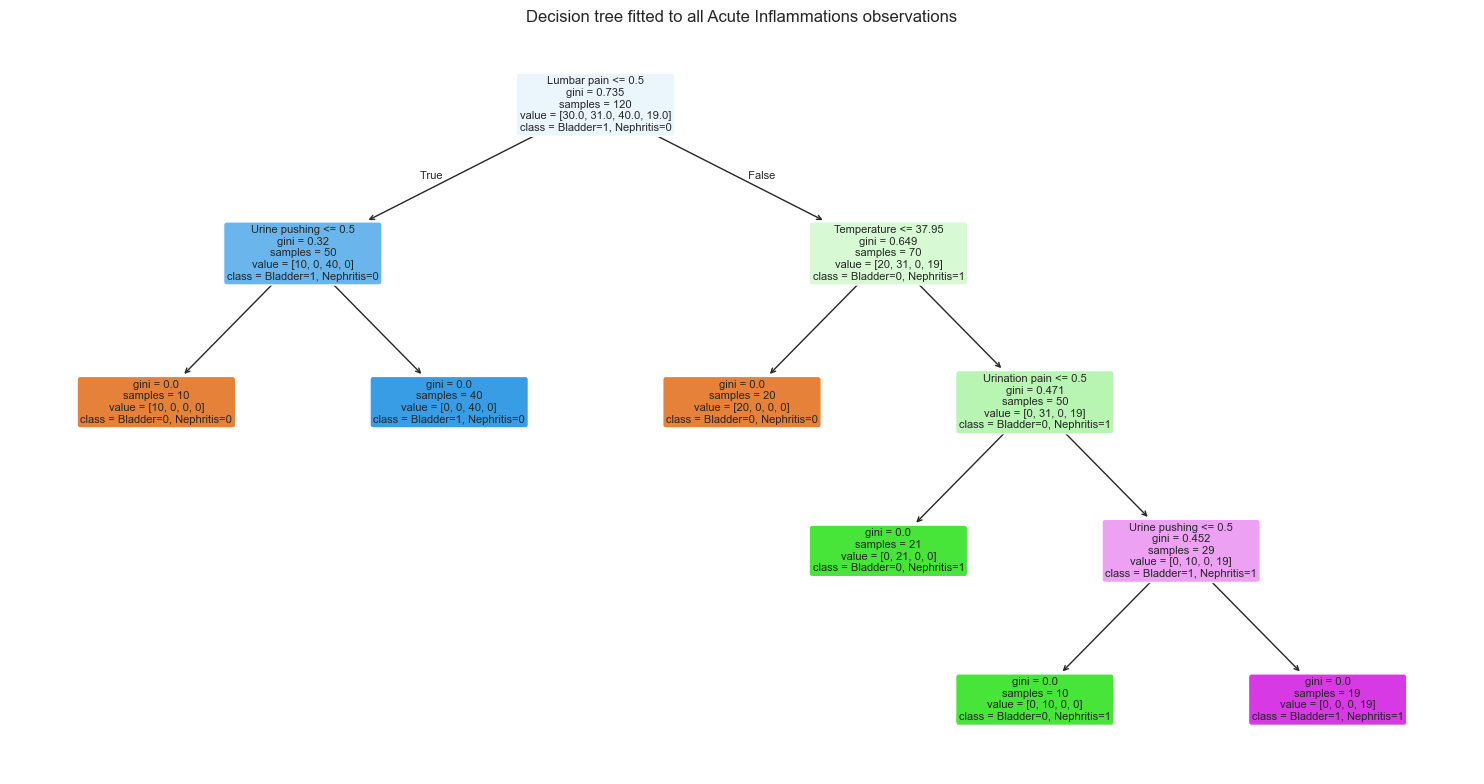

In [3]:
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
full_tree.fit(symptoms, diagnosis_class)

print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())
print("Training accuracy:", round(full_tree.score(symptoms, diagnosis_class), 4))

plt.figure(figsize=(15, 8))
plot_tree(
    full_tree,
    feature_names=symptom_names,
    class_names=full_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("Decision tree fitted to all Acute Inflammations observations")
plt.tight_layout()
plt.show()

The full tree has depth 4, six leaves, and 100% training accuracy. Its main splits use lumbar pain, urine pushing, temperature, and urination pain. Since the same data were used to fit and score the tree, this is not a test-set accuracy.

### 1(c) Convert the fitted tree into IF-THEN rules

In [4]:
def tree_rules(model, feature_names):
    """Return one IF-THEN rule for every leaf in a fitted tree."""
    structure = model.tree_
    rules = []

    def walk(node, conditions):
        is_leaf = structure.children_left[node] == structure.children_right[node]
        if is_leaf:
            class_index = structure.value[node][0].argmax()
            prediction = model.classes_[class_index]
            rules.append(
                f"IF {' AND '.join(conditions) or 'TRUE'} THEN {prediction}"
            )
            return

        feature = feature_names[structure.feature[node]]
        threshold = structure.threshold[node]
        walk(
            structure.children_left[node],
            conditions + [f"{feature} <= {threshold:.2f}"],
        )
        walk(
            structure.children_right[node],
            conditions + [f"{feature} > {threshold:.2f}"],
        )

    walk(0, [])
    return rules


full_rules = tree_rules(full_tree, symptom_names)
for rule_number, rule in enumerate(full_rules, start=1):
    print(f"Rule {rule_number}: {rule}")

Rule 1: IF Lumbar pain <= 0.50 AND Urine pushing <= 0.50 THEN Bladder=0, Nephritis=0
Rule 2: IF Lumbar pain <= 0.50 AND Urine pushing > 0.50 THEN Bladder=1, Nephritis=0
Rule 3: IF Lumbar pain > 0.50 AND Temperature <= 37.95 THEN Bladder=0, Nephritis=0
Rule 4: IF Lumbar pain > 0.50 AND Temperature > 37.95 AND Urination pain <= 0.50 THEN Bladder=0, Nephritis=1
Rule 5: IF Lumbar pain > 0.50 AND Temperature > 37.95 AND Urination pain > 0.50 AND Urine pushing <= 0.50 THEN Bladder=0, Nephritis=1
Rule 6: IF Lumbar pain > 0.50 AND Temperature > 37.95 AND Urination pain > 0.50 AND Urine pushing > 0.50 THEN Bladder=1, Nephritis=1


The full tree produces six IF-THEN rules, one for each leaf. Binary symptoms split at 0.5, while temperature uses its measured Celsius value.

### 1(d) Cost-complexity pruning and an interpretable alternative

In [5]:
pruning_path = full_tree.cost_complexity_pruning_path(
    symptoms, diagnosis_class
)
candidate_alphas = np.unique(pruning_path.ccp_alphas)

tree_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
pruning_rows = []

for alpha in candidate_alphas:
    candidate = DecisionTreeClassifier(
        ccp_alpha=alpha, random_state=RANDOM_STATE
    )
    fold_scores = cross_val_score(
        candidate,
        symptoms,
        diagnosis_class,
        cv=tree_cv,
        scoring="accuracy",
    )
    candidate.fit(symptoms, diagnosis_class)
    pruning_rows.append({
        "ccp_alpha": alpha,
        "Mean CV accuracy": fold_scores.mean(),
        "CV accuracy SD": fold_scores.std(ddof=1),
        "Depth": candidate.get_depth(),
        "Leaves": candidate.get_n_leaves(),
        "Training accuracy": candidate.score(symptoms, diagnosis_class),
    })

pruning_results = pd.DataFrame(pruning_rows)
display(pruning_results.round(5))

,ccp_alpha,Mean CV accuracy,CV accuracy SD,Depth,Leaves,Training accuracy
0,0.00000,0.99167,0.01863,4,6,1.00000
1,0.09817,0.85833,0.05590,2,4,0.84167
2,0.13333,0.76667,0.06972,2,3,0.75833
3,0.18200,0.67500,0.07454,1,2,0.59167
4,0.22292,0.48333,0.13693,0,1,0.33333


In [6]:
best_index = pruning_results["Mean CV accuracy"].idxmax()
cv_best_alpha = pruning_results.loc[best_index, "ccp_alpha"]

# The first positive path value is the least aggressive penalty that actually
# removes branches from the fitted full-data tree.
compact_alpha = candidate_alphas[candidate_alphas > 0].min()
compact_tree = DecisionTreeClassifier(
    ccp_alpha=compact_alpha, random_state=RANDOM_STATE
).fit(symptoms, diagnosis_class)

print("CV-optimal alpha:", round(cv_best_alpha, 6))
print("First alpha that simplifies the tree:", round(compact_alpha, 6))

CV-optimal alpha: 0.0
First alpha that simplifies the tree: 0.098167


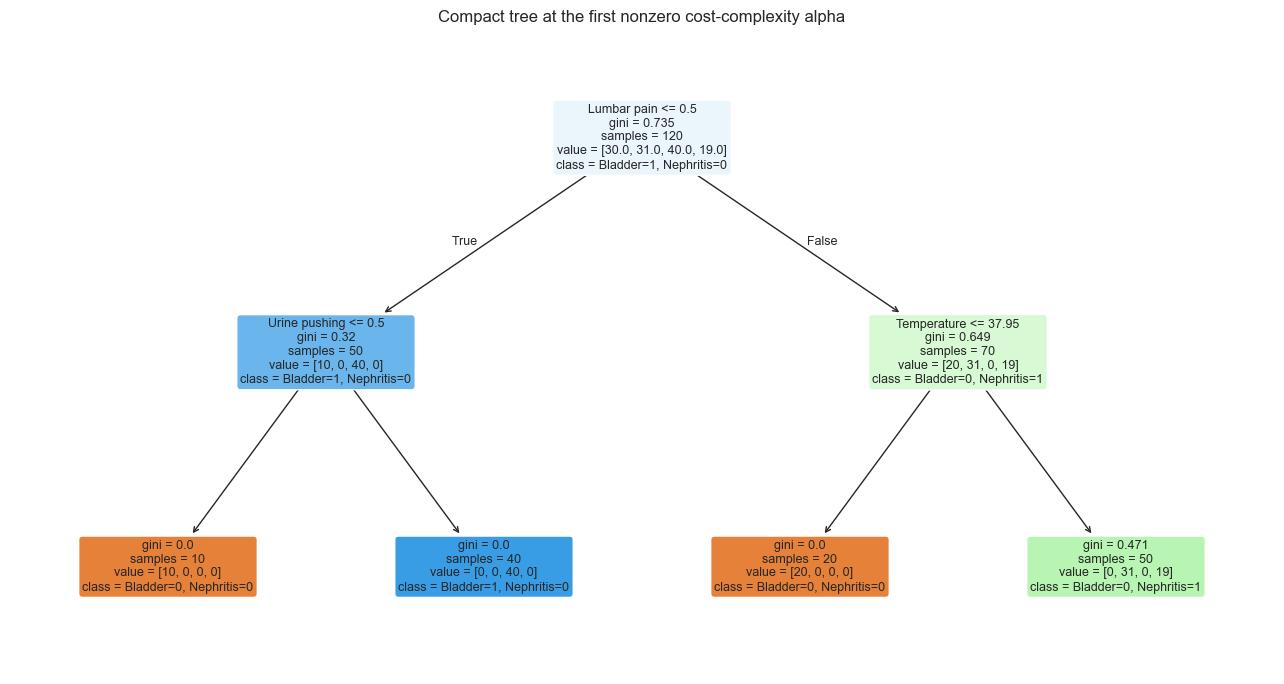

Rule 1: IF Lumbar pain <= 0.50 AND Urine pushing <= 0.50 THEN Bladder=0, Nephritis=0
Rule 2: IF Lumbar pain <= 0.50 AND Urine pushing > 0.50 THEN Bladder=1, Nephritis=0
Rule 3: IF Lumbar pain > 0.50 AND Temperature <= 37.95 THEN Bladder=0, Nephritis=0
Rule 4: IF Lumbar pain > 0.50 AND Temperature > 37.95 THEN Bladder=0, Nephritis=1


In [7]:
plt.figure(figsize=(13, 7))
plot_tree(
    compact_tree,
    feature_names=symptom_names,
    class_names=compact_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Compact tree at the first nonzero cost-complexity alpha")
plt.tight_layout()
plt.show()

compact_rules = tree_rules(compact_tree, symptom_names)
for rule_number, rule in enumerate(compact_rules, start=1):
    print(f"Rule {rule_number}: {rule}")

Cross-validation prefers $\alpha=0$ with mean accuracy 0.9917, so pruning is not helpful if accuracy is the main goal. The first nonzero value, $\alpha=0.09817$, gives a shorter four-rule tree but lowers mean CV accuracy to 0.8583. The six-rule tree is still small, so I would keep it unless the shorter rule list is more important than accuracy.

## 2. The LASSO and Boosting for Regression

### 2(a) Load the Communities and Crime data and create the prescribed split

In [8]:
with open(DATA_DIR / "communities.names", encoding="utf-8") as file:
    attribute_names = re.findall(
        r"(?im)^@attribute\s+(\S+)", file.read()
    )

crime_data = pd.read_csv(
    DATA_DIR / "communities.data",
    names=attribute_names,
    na_values="?",
)

nonpredictive_columns = [
    "state", "county", "community", "communityname", "fold"
]
target_name = "ViolentCrimesPerPop"

crime_predictors = crime_data.drop(
    columns=nonpredictive_columns + [target_name]
)
crime_target = crime_data[target_name]

In [9]:
crime_target.head()

0    0.20
1    0.67
2    0.43
3    0.12
4    0.03
Name: ViolentCrimesPerPop, dtype: float64

In [10]:
X_train = crime_predictors.iloc[:1495].copy()
X_test = crime_predictors.iloc[1495:].copy()
y_train = crime_target.iloc[:1495].copy()
y_test = crime_target.iloc[1495:].copy()

print("Raw data shape:", crime_data.shape)
print("Predictor count after removing identifiers:", X_train.shape[1])
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Raw data shape: (1994, 128)
Predictor count after removing identifiers: 122
Training shape: (1495, 122)
Test shape: (499, 122)


The file has 1,994 rows and 128 columns. After removing the five identifier columns and the response, 122 predictors remain. The first 1,495 rows are training data and the final 499 are test data.

### 2(b) Impute missing predictor values

In [11]:
eda_imputer = SimpleImputer(strategy="median")
imputed_train = pd.DataFrame(
    eda_imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)

print("Missing values in raw training predictors:", int(X_train.isna().sum().sum()))
print("Missing values in raw test predictors:", int(X_test.isna().sum().sum()))
print("Missing values after training imputation:", int(imputed_train.isna().sum().sum()))

Missing values in raw training predictors: 27633
Missing values in raw test predictors: 9218
Missing values after training imputation: 0


The training predictors contain 27,633 missing entries and the test predictors contain 9,218. I use median imputation. For model tuning, the imputer stays inside each pipeline so validation data do not influence the fitted medians.

### 2(c) Plot and inspect the feature correlation matrix

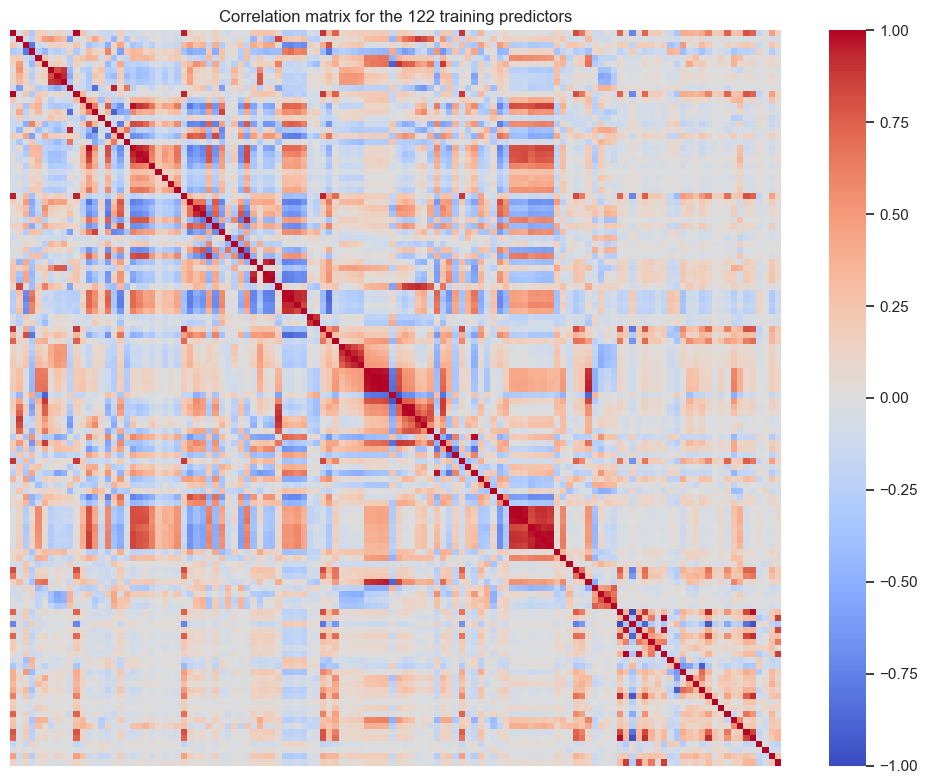

,Feature 1,Feature 2,Absolute correlation
0,LemasSwFTPerPop,PolicPerPop,1.00000
1,PctRecImmig8,PctRecImmig10,0.99556
2,OwnOccLowQuart,OwnOccMedVal,0.99469
3,LemasSwornFT,LemasSwFTFieldOps,0.99450
4,population,numbUrban,0.99361
5,PctRecImmig5,PctRecImmig8,0.99274
6,OwnOccMedVal,OwnOccHiQuart,0.99156
7,PctRecentImmig,PctRecImmig5,0.98936
8,RentMedian,MedRent,0.98878
9,PctFam2Par,PctKids2Par,0.98562


In [12]:
feature_correlations = imputed_train.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    feature_correlations,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False,
)
plt.title("Correlation matrix for the 122 training predictors")
plt.tight_layout()
plt.show()

upper_triangle = feature_correlations.abs().where(
    np.triu(np.ones(feature_correlations.shape), k=1).astype(bool)
)
strongest_pairs = upper_triangle.stack().nlargest(10)
pair_table = strongest_pairs.rename("Absolute correlation").reset_index()
pair_table.columns = ["Feature 1", "Feature 2", "Absolute correlation"]
display(pair_table)

Several groups of predictors are highly correlated. For example, `LemasSwFTPerPop` and `PolicPerPop` are perfectly correlated after imputation, and several immigration and housing variables have correlations above 0.99. This supports trying Ridge, Lasso, and PCR.

### 2(d) Calculate the coefficient of variation for every predictor

In [13]:
feature_means = imputed_train.mean()
feature_sds = imputed_train.std(ddof=1)
coefficient_of_variation = (
    feature_sds / feature_means.replace(0, np.nan)
).sort_values(ascending=False)

cv_table = coefficient_of_variation.rename("CV").to_frame()
print("CV values calculated:", len(cv_table))
display(cv_table.head(11).round(3))

CV values calculated: 122


,CV
PctPolicAsian,5.527
NumStreet,4.293
NumInShelters,3.471
NumIlleg,3.059
NumImmig,2.927
LemasPctOfficDrugUn,2.553
NumUnderPov,2.342
LemasSwornFT,2.248
population,2.241
numbUrban,2.038


CV is calculated for all 122 predictors. The largest values mostly belong to variables with means close to zero. A high CV means high relative variation; it does not automatically mean that a feature is important for predicting crime.

### 2(e) Plot the $\lfloor\sqrt{128}\rfloor=11$ predictors with the largest CV

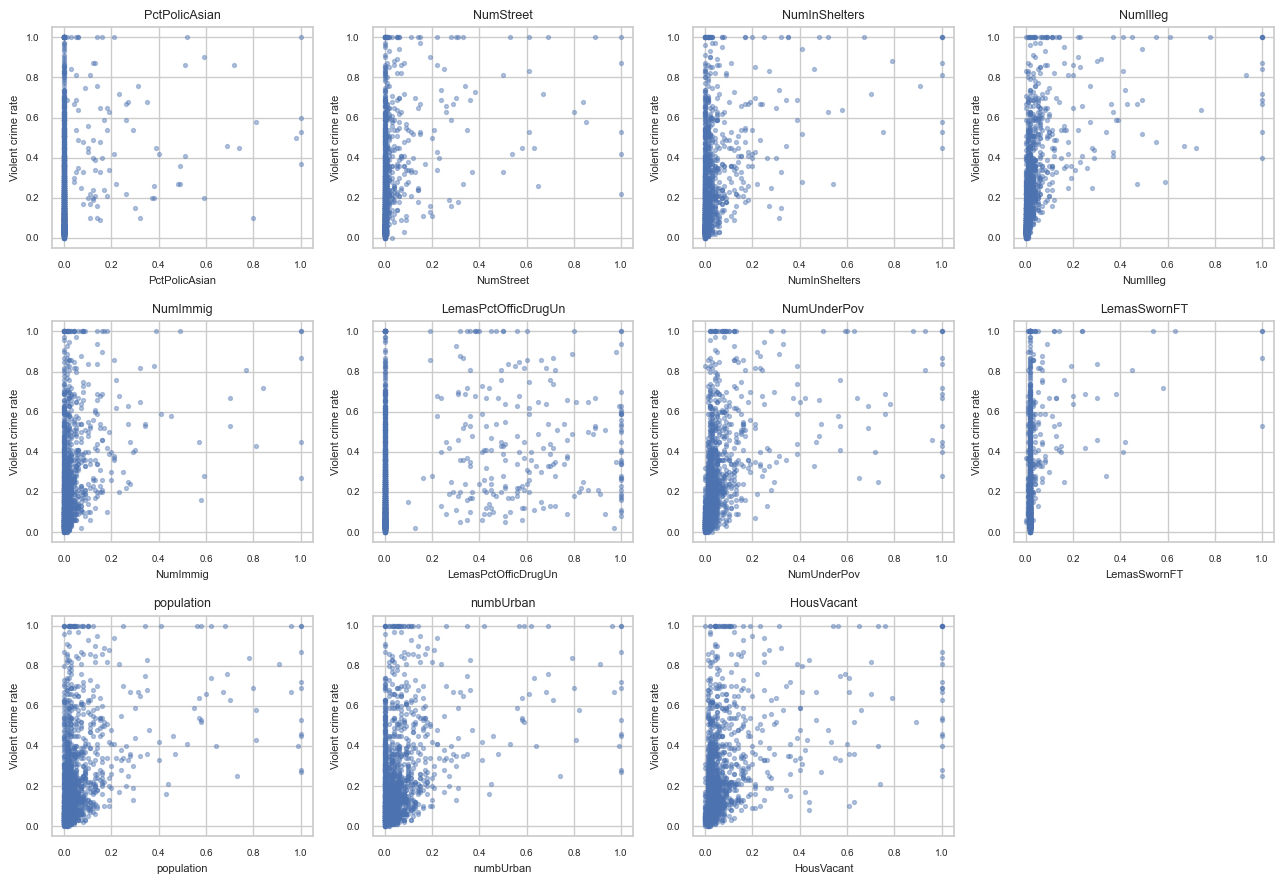

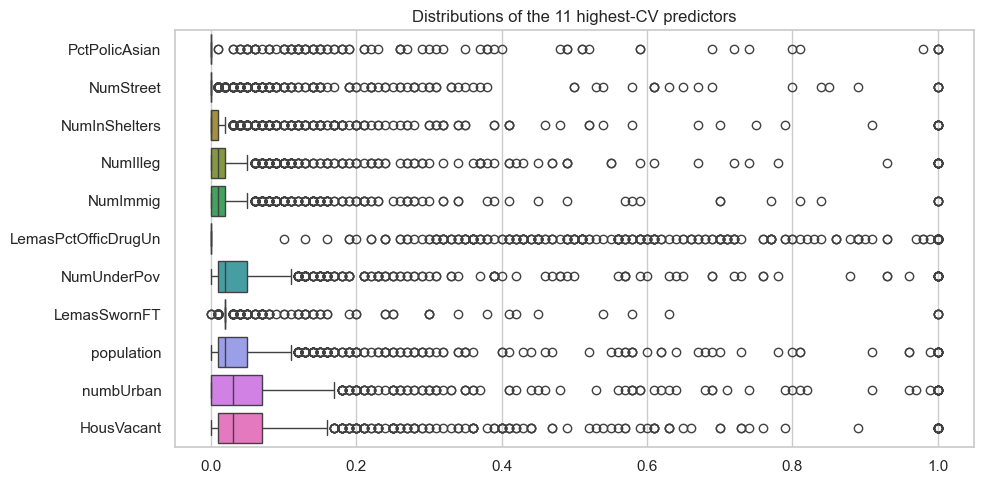

,CV,Correlation with response
PctPolicAsian,5.527,0.201
NumStreet,4.293,0.332
NumInShelters,3.471,0.373
NumIlleg,3.059,0.463
NumImmig,2.927,0.295
LemasPctOfficDrugUn,2.553,0.332
NumUnderPov,2.342,0.442
LemasSwornFT,2.248,0.277
population,2.241,0.364
numbUrban,2.038,0.362


In [14]:
number_to_plot = int(np.floor(np.sqrt(crime_data.shape[1])))
high_cv_features = coefficient_of_variation.dropna().head(number_to_plot).index

fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for ax, feature in zip(axes.flat, high_cv_features):
    ax.scatter(
        imputed_train[feature], y_train,
        s=8, alpha=0.4
    )
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel(feature, fontsize=8)
    ax.set_ylabel("Violent crime rate", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes.flat[len(high_cv_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=imputed_train[high_cv_features], orient="h")
plt.title("Distributions of the 11 highest-CV predictors")
plt.tight_layout()
plt.show()

high_cv_summary = pd.DataFrame({
    "CV": coefficient_of_variation[high_cv_features],
    "Correlation with response": [
        imputed_train[feature].corr(y_train)
        for feature in high_cv_features
    ],
})
display(high_cv_summary.round(3))

The 11 high-CV variables are mostly sparse or strongly right-skewed. Their correlations with crime rate are positive but only moderate. The scatterplots show patterns and outliers, but they are not enough to establish statistical significance because they do not measure uncertainty or control for other predictors.

### Model setup for 2(f)-2(j)

I use five-fold cross-validation on the training set for every tuning step. The test set is only used to report the final error. Test error is measured with mean squared error (MSE), and I also show RMSE to keep the scale easier to read.

In [15]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_results = []


def report_test_error(name, model):
    predictions = model.predict(X_test)
    mse = mean_squared_error(y_test, predictions)
    model_results.append([name, mse, np.sqrt(mse)])
    print(f"Test MSE: {mse:.5f}")
    print(f"Test RMSE: {np.sqrt(mse):.5f}")

### 2(f) Least-squares regression

In [16]:
least_squares = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression(),
)
least_squares.fit(X_train, y_train)
report_test_error("Least squares", least_squares)

Test MSE: 0.01797
Test RMSE: 0.13404


Least squares has test MSE 0.01797 and RMSE 0.13404. This gives a useful baseline for the regularized and nonlinear models.

### 2(g) Ridge regression with cross-validated $\lambda$

In [17]:
ridge_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    Ridge(),
)

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"ridge__alpha": np.logspace(-3, 5, 30)},
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
ridge_search.fit(X_train, y_train)

ridge_model = ridge_search.best_estimator_
print("Best lambda:", ridge_search.best_params_["ridge__alpha"])
report_test_error("Ridge", ridge_model)

Best lambda: 92.36708571873865
Test MSE: 0.01741
Test RMSE: 0.13195


Cross-validation chooses $\lambda=92.3671$. Ridge has test MSE 0.01741, which is slightly better than least squares. This small improvement is reasonable because many predictors are strongly correlated.

### 2(h) Lasso with and without additional standardization

In [ ]:
lasso_grid = {"lasso__alpha": np.logspace(-5, -0.3, 30)}

lasso_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    Lasso(max_iter=100000, tol=1e-6),
)

In [ ]:
lasso_search = GridSearchCV(
    lasso_pipeline,
    lasso_grid,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
lasso_search.fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_

In [ ]:
standard_lasso_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    Lasso(max_iter=100000, tol=1e-6),
)
standard_lasso_search = GridSearchCV(
    standard_lasso_pipeline,
    lasso_grid,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
standard_lasso_search.fit(X_train, y_train)
standard_lasso_model = standard_lasso_search.best_estimator_

In [ ]:
print("Provided-scale alpha:", lasso_search.best_params_["lasso__alpha"])
report_test_error("Lasso: provided scale", lasso_model)
print("Standardized alpha:", standard_lasso_search.best_params_["lasso__alpha"])
report_test_error("Lasso: standardized", standard_lasso_model)

for label, model in [
    ("Provided scale", lasso_model),
    ("Standardized", standard_lasso_model),
]:
    coefficients = model.named_steps["lasso"].coef_
    selected = X_train.columns[np.abs(coefficients) > 1e-8]
    print(f"\n{label}: {len(selected)} selected variables")
    print(", ".join(selected))

Provided-scale alpha: 9.384557359249333e-05
Test MSE: 0.01767
Test RMSE: 0.13293
Standardized alpha: 0.0006063992014156964
Test MSE: 0.01773
Test RMSE: 0.13316

Provided scale: 76 selected variables
racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCost

The provided-scale Lasso selects 76 variables and has test MSE 0.01767. The standardized version selects 75 and has MSE 0.01773. Their results are close because the original predictors are already normalized. Additional standardization does not improve the test error in this split.

### 2(i) Principal components regression with cross-validated $M$

In [19]:
pcr_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PCA(svd_solver="full"),
    LinearRegression(),
)

pcr_search = GridSearchCV(
    pcr_pipeline,
    {"pca__n_components": range(1, X_train.shape[1] + 1)},
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
pcr_search.fit(X_train, y_train)
pcr_model = pcr_search.best_estimator_

print("Best number of components:", pcr_search.best_params_["pca__n_components"])
report_test_error("PCR", pcr_model)

Best number of components: 93
Test MSE: 0.01826
Test RMSE: 0.13515


PCR selects 93 components and has test MSE 0.01826. It is slightly worse than the other linear methods. PCA keeps directions with high predictor variance, but those directions are not always the best ones for predicting crime rate.

### 2(j) L1-regularized gradient boosting with cross-validated $\alpha$

In [20]:
boosting_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
)

boosting_search = GridSearchCV(
    boosting_pipeline,
    {"xgbregressor__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 5, 10]},
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
boosting_search.fit(X_train, y_train)
boosting_model = boosting_search.best_estimator_

print("Best alpha:", boosting_search.best_params_["xgbregressor__reg_alpha"])
report_test_error("XGBoost", boosting_model)

Best alpha: 1
Test MSE: 0.01624
Test RMSE: 0.12744


In [21]:
comparison = pd.DataFrame(
    model_results,
    columns=["Model", "Test MSE", "Test RMSE"],
).set_index("Model")

display(comparison.sort_values("Test MSE").round(5))

,Test MSE,Test RMSE
Model,,
XGBoost,0.01624,0.12744
Ridge,0.01741,0.13195
Lasso: provided scale,0.01767,0.13293
Lasso: standardized,0.01773,0.13316
Least squares,0.01797,0.13404
PCR,0.01826,0.13515


Cross-validation chooses XGBoost $\alpha=1$. XGBoost has the lowest test MSE, 0.01624, while Ridge is the best linear method at 0.01741. The improvement suggests that nonlinear effects or interactions may be useful, although the difference comes from one fixed test set and should be interpreted cautiously.